# Assignment 11: Spatial community composition — blobs or stripes?

### **This is an imaginary exercise.**

Maine can protect **1,000 km²** as two compact **blob** parks or two long,
narrow **stripe** parks. Each park covers 500 km². Which design would you
recommend for conserving amphibian diversity?

Follow the analyses in [Lab10](../labs/Lab10-CommunityComposition.ipynb), now
comparing park shapes. You may reuse its code and functions. Complete the code cells 
and short answers. Submit this notebook with its maps, tables, and saved summary CSVs.

## The data

[`ME_BlobStripeParks.geojson`](../data/ME_BlobStripeParks.geojson) contains two
roughly round blobs and two elliptical stripes, five times as long as they
are wide. All four are imaginary, nonoverlapping, and within Maine and the
source sample bounds. Each point already has a park assignment.

Sampling follows Lab10. All real records inside these parks are retained.
All source records in `amphibians.geojson` determine each observed species'
convex hull, its 50 km buffer, and its record-count weight. Each of **50 invented
species** inherits the buffered range and abundance weight of a randomly
sampled observed species. Added points are sampled within those ranges'
intersections with the parks, with counts proportional to the observed or
inherited weights. One point per invented species is reserved. There are
**1,500 total points**, including originals; seed = 597.

`synthetic` identifies generated points; `imaginary_species` identifies invented
taxa.

## 1. Import packages and load the data

Run from `docs/assignments` using the same environment as Lab10.

In [1]:
from pathlib import Path

import geopandas as gpd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import entropy
from scipy.spatial.distance import jaccard, braycurtis

AREA_CRS = "EPSG:5070"
COLORS = {"blob": "forestgreen", "stripe": "darkorange"}
designs = ["blob", "stripe"]

In [2]:
features = gpd.read_file("../data/ME_BlobStripeParks.geojson")
parks = features[features.feature_type == "park"].copy()
parks = parks.to_crs(AREA_CRS).set_index("park_id")
records = features[features.feature_type == "occurrence"].copy().to_crs(AREA_CRS)
park_order = list(parks.index)

display(parks[["park_name", "scenario", "area_km2"]])
print("Total occurrence records:", len(records))

,park_name,scenario,area_km2
park_id,,,
B1,Alder Crown Preserve,blob,500.0
B2,Hemlock Hollow Reserve,blob,500.0
S1,Fern Ribbon Preserve,stripe,500.0
S2,Silver Brook Reach,stripe,500.0


Total occurrence records: 1500


## 2. Map the parks and check the comparison

Map the four polygons and their points, using one color per design. Label the
park IDs. A simple map is enough.

Calculate area in km² and show the total area and number of occurrence records
for each design. Keep all records, including generated points and invented
species, in the analyses below.

scenario
blob      1000.000589
stripe    1000.000753
Name: measured_km2, dtype: float64

# of occurrence records:  1500


scenario
blob      845
stripe    655
dtype: int64

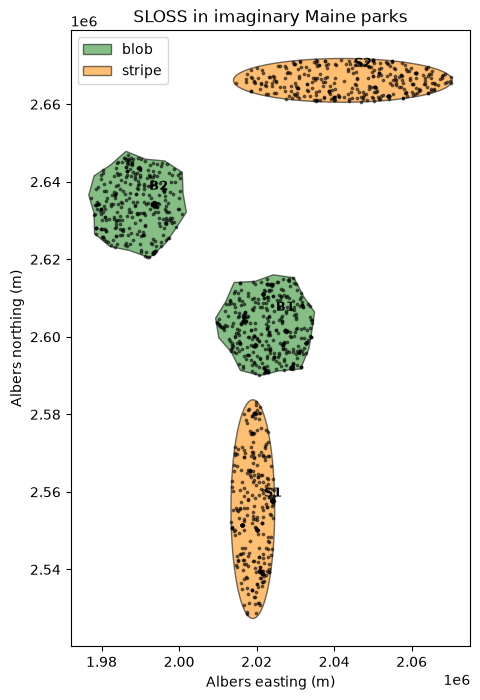

In [13]:
parks["measured_km2"] = parks.area / 1e6
display(parks.groupby("scenario").measured_km2.sum())

# Count records in each design with records.groupby("scenario").size().

print("# of occurrence records: ", len(records))
display(records.groupby("scenario").size())

# Plot the parks and occurrence points; label B1, B2, S1, and S2.

fig, ax = plt.subplots(figsize=(8, 8))

for strategy, group in parks.groupby("scenario"):
    group.plot(ax=ax, color=COLORS[strategy], alpha=0.55, edgecolor="black", label=strategy)

records.plot(ax=ax, color="black", markersize=3, alpha=0.5)

for row in parks.itertuples():
    anchor = row.geometry.representative_point()
    ax.annotate(
        row.Index,
        (anchor.x, anchor.y),
        xytext=(8, 10),
        textcoords="offset points",
        fontsize=9,
        fontweight="bold"
    )

ax.set(
    title="SLOSS in imaginary Maine parks",
    xlabel="Albers easting (m)",
    ylabel="Albers northing (m)"
)
ax.legend()
plt.show()

**Interpretation:** What is held equal between the designs? What differs besides
shape? Predict which design will capture more species, and explain why.

*Your answer:* The total protected area is equal between the designs and things like edge-to-area ratio would differ. The edge-to-area and connectivity would change since several small parks have much more perimeter per unit area and they will lack the connectivity that a larger single block would have.

## 3. Build the community matrix

Rows are parks; columns are species; entries are record counts. A zero means
no records of that species in that park. It does not establish true absence.

In [14]:
community = pd.crosstab(records.park_id, records.species)
community = community.reindex(park_order, fill_value=0)
presence = community > 0

display(community)

species,Ambystoma laterale,Ambystoma maculatum,Anaxyrus americanus,Aquarana clamitans,Aquarana septentrionalis,Boreorana sylvatica,Desmognathus fuscus,Dryophytes versicolor,Eurycea bislineata,Fictotriton alderi,...,Sylvophantoma glacialina,Sylvophantoma hazelii,Sylvophantoma inverna,Sylvophantoma kettleii,Sylvophantoma lichenosa,Sylvophantoma mapleii,Sylvophantoma noctiluca,Sylvophantoma sprucea,Sylvophantoma willowii,Sylvophantoma zephyra
park_id,,,,,,,,,,,,,,,,,,,,,
B1,1,15,47,38,0,37,0,21,1,0,...,0,0,0,3,4,2,1,0,0,8
B2,1,17,39,21,0,26,3,11,5,0,...,0,0,1,5,5,8,0,1,1,5
S1,0,5,47,18,0,22,3,18,6,0,...,1,0,0,2,3,2,0,0,1,5
S2,1,7,11,19,1,13,0,11,4,1,...,0,1,0,3,10,5,1,1,0,8


How many species occur in the whole dataset? Choose one species and describe
its distribution among the four parks using its column in `community`.

*Your answer:* 67 columns, so 66 species. Aquarana septentrionalis seems to be a more rare species as it is not found in B1, B2, or S1, and only one occurence in S2. 

## 4. Richness, Shannon diversity, and evenness

Use the lab's function below. Shannon uses `scipy.stats.entropy`; larger values
reflect more species, greater evenness, or both.

In [15]:
def diversity(community_counts):
    results = pd.DataFrame(
        index=community_counts.index,
        columns=["n_records", "richness", "shannon"],
        dtype=float,
    )
    for unit, counts in community_counts.iterrows():
        species_present = counts[counts > 0]
        results.loc[unit, "n_records"] = counts.sum()
        if len(species_present) == 0:
            continue
        results.loc[unit, "richness"] = len(species_present)
        results.loc[unit, "shannon"] = entropy(species_present)
    return results

,n_records,richness,shannon,evenness,park_name,scenario
park_id,,,,,,
B1,436.0,51.0,3.323911,0.544485,Alder Crown Preserve,blob
B2,409.0,54.0,3.516299,0.623327,Hemlock Hollow Reserve,blob
S1,328.0,49.0,3.320299,0.564666,Fern Ribbon Preserve,stripe
S2,327.0,57.0,3.711955,0.718136,Silver Brook Reach,stripe


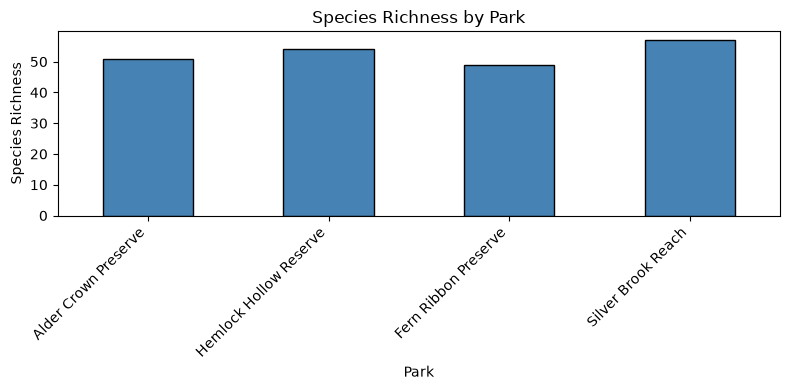

In [17]:
# Calculate park_metrics = diversity(community).
# Add park names and scenarios from parks.
# Add evenness = np.exp(shannon) / richness, as in Lab10.
# Display the table and make a simple richness or Shannon plot.

def diversity(community_counts):
    results = pd.DataFrame(
        index=community_counts.index,
        columns=["n_records", "richness", "shannon"],
        dtype=float,
    )
    for unit, counts in community_counts.iterrows():
        species_present = counts[counts > 0]
        results.loc[unit, "n_records"] = counts.sum()
        if len(species_present) == 0:
            continue
        results.loc[unit, "richness"] = len(species_present)
        results.loc[unit, "shannon"] = entropy(species_present)
    return results

park_metrics = diversity(community)
# Calculate evenesss
park_metrics["evenness"] = np.exp(park_metrics["shannon"])/park_metrics["richness"]
park_metrics["park_name"] = parks.park_name
park_metrics["scenario"] = parks.scenario
display(park_metrics)

ax = park_metrics.plot.bar(
    x="park_name",
    y="richness",
    legend=False,
    color="steelblue",
    edgecolor="black",
    figsize=(8, 4)
)
ax.set(
    title="Species Richness by Park",
    xlabel="Park",
    ylabel="Species Richness"
)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Does the richest park also have the highest Shannon diversity and evenness?
What would adding 100 records of an already common species do to these measures?

*Your answer:* Yes, S2 has the highest richness, the highest Shannon diversity, and the highest evenness. Adding 100 records of an already common species would keep the richness unchanged but it would decrease both Shannon diversity and evenness. 

## 5. Alpha, beta, and gamma diversity

Pool the two blob parks, then the two stripe parks. For each design, calculate:

- **Alpha:** mean richness of its two parks.
- **Gamma:** richness in the pooled species list.
- **Multiplicative beta:** gamma divided by alpha.
- Total records and pooled Shannon diversity.

Keep the park rows in `community`; use `design_counts` for the pooled rows.

In [19]:
design_counts = pd.DataFrame(index=designs, columns=community.columns, dtype=float)
for design in designs:
    park_ids = parks[parks.scenario == design].index
    design_counts.loc[design] = community.loc[park_ids].sum()

# Use diversity(design_counts) to start design_metrics.
# Rename its richness column to gamma_richness.
# For each design, find its two rows in park_metrics.
# Calculate mean_park_alpha and beta_ratio, then display design_metrics.

strategies = ["blob", "stripe"]
strategy_counts = pd.DataFrame(
    index=strategies, columns=community.columns, dtype=float
)
for strategy in strategies:
    park_ids = parks[parks.scenario == strategy].index
    strategy_counts.loc[strategy] = community.loc[park_ids].sum()

strategy_metrics = diversity(strategy_counts)
strategy_metrics = strategy_metrics.rename(columns={"richness": "gamma_richness"})
for strategy in strategies:
    local_parks = park_metrics[park_metrics.scenario == strategy]
    alpha = local_parks.richness.mean()
    gamma = strategy_metrics.loc[strategy, "gamma_richness"]
    strategy_metrics.loc[strategy, "mean_park_alpha"] = alpha
    strategy_metrics.loc[strategy, "beta_ratio"] = gamma / alpha
    strategy_metrics.loc[strategy, "sum_park_richness"] = local_parks.richness.sum()
    strategy_metrics.loc[strategy, "area_km2"] = parks[parks.scenario == strategy].measured_km2.sum()
display(strategy_metrics)

,n_records,gamma_richness,shannon,mean_park_alpha,beta_ratio,sum_park_richness,area_km2
blob,845.0,60.0,3.460793,52.5,1.142857,105.0,1000.000589
stripe,655.0,63.0,3.606102,53.0,1.188679,106.0,1000.000753


Which design has higher gamma diversity? Does alpha or complementarity between
its two parks help explain the result? Why is pooled richness generally smaller
than the sum of the two park richnesses?

List species recorded only in blobs and species recorded only in stripes.
Hint: make a `set` from the species with positive counts in each pooled row;
subtract one set from the other.

*Your answer:* Stripe has higher gamma diversity and a higher Shannon diversity even though it had fewer total occurence records than blob. Alpha or complentarity between its two parks both contribute with beta diversity playing the larger role. The pooled richness is generally smaller than the sum of the two park richnessess because the two parks shaare many of the same species. 

In [21]:
# Make blob_species and stripe_species from design_counts.
# Print species unique to each design.

blob_counts = design_counts.loc["blob"]
stripe_counts = design_counts.loc["stripe"]

blob_species = set(blob_counts[blob_counts > 0].index)
stripe_species = set(stripe_counts[stripe_counts > 0].index)

print("Only in the blob parks:", sorted(blob_species - stripe_species))
print("Only in the stripe parks:", sorted(stripe_species - blob_species))
print("In both designs:", len(blob_species & stripe_species))



Only in the blob parks: ['Imaginarana emberi', 'Imaginarana muscosa', 'Imaginarana rivularis', 'Sylvophantoma inverna']
Only in the stripe parks: ['Aquarana septentrionalis', 'Fictotriton alderi', 'Fictotriton vernalensis', 'Rana arvalis', 'Sylvophantoma cedrina', 'Sylvophantoma glacialina', 'Sylvophantoma hazelii']
In both designs: 56


### Jaccard dissimilarity

Jaccard compares presence/absence: 0 means identical species lists; 1 means no
shared species. Use `scipy.spatial.distance.jaccard` on rows of `presence`.

In [24]:
print("B1 versus B2:", jaccard(presence.loc["B1"], presence.loc["B2"]))

# Build jaccard_distances, a four-by-four table, as in Lab10.
# Use nested loops over park_order and jaccard(presence.loc[a], presence.loc[b]).
# Display the table.

jaccard_distances = pd.DataFrame(index=park_order, columns=park_order, dtype=float)

for park_a in park_order:
    for park_b in park_order:
        jaccard_distances.loc[park_a, park_b] = jaccard(
            presence.loc[park_a], presence.loc[park_b]
        )

display(jaccard_distances.round(2))


B1 versus B2: 0.25


,B1,B2,S1,S2
B1,0.00,0.25,0.25,0.20
B2,0.25,0.00,0.28,0.27
S1,0.25,0.28,0.00,0.32
S2,0.20,0.27,0.32,0.00


Compare B1–B2 with S1–S2. Which design's two parks have more different species
lists? Does that agree with the beta ratios? Explain why Jaccard alone cannot
distinguish species replacement from differences in richness.

*Your answer:* Stripe design has more different species with a Jaccard distance of .32 compared to .25 for blob design. This means that for stripe, 32% of their combined species are unique to only one of the two parks whereas for blob, only 25% is unique to one park. Jaccard cannot distinguish species replacement from richness differences because Jaccard distance only counts the total fraction of species that aren't shared between two parks, so it can't tell whether two parks have different species or one park simply has fewer species.

### Bray–Curtis dissimilarity

Use `scipy.spatial.distance.braycurtis` on record counts. Make a second
four-by-four table, `bray_curtis_distances`.

Then repeat the B1–B2 and S1–S2 comparisons using **relative frequencies**:
divide each park's species counts by its total records before calling
`braycurtis`.

In [26]:
print("B1 versus B2:", braycurtis(community.loc["B1"], community.loc["B2"]))

# Build and display bray_curtis_distances using the Jaccard loop pattern.
# For each within-design pair, divide each row by its sum and compare again.
from scipy.spatial.distance import braycurtis

bray_curtis_distances = pd.DataFrame(index=park_order, columns=park_order, dtype=float)
for park_a in park_order:
    for park_b in park_order:
        bray_curtis_distances.loc[park_a, park_b] = braycurtis(
            community.loc[park_a], community.loc[park_b]
        )
display(bray_curtis_distances.round(2))

rel_community = community.div(community.sum(axis=1), axis=0)

print("Relative abundance B1 versus B2:", round(braycurtis(rel_community.loc["B1"], rel_community.loc["B2"]), 2))
print("Relative abundance S1 versus S2:", round(braycurtis(rel_community.loc["S1"], rel_community.loc["S2"]), 2))


B1 versus B2: 0.19763313609467456


,B1,B2,S1,S2
B1,0.00,0.20,0.24,0.33
B2,0.20,0.00,0.25,0.27
S1,0.24,0.25,0.00,0.30
S2,0.33,0.27,0.30,0.00


Relative abundance B1 versus B2: 0.19
Relative abundance S1 versus S2: 0.3


Do Jaccard and Bray–Curtis tell the same story? What information does Bray–Curtis
add? Why can unequal record totals affect its values, and what changes when
you use relative frequencies?

*Your answer:* Jaccard and Bray-Curtis tell the same story and both show that S1 and S2 are more dissimilar from each other than the B1-B2 are. Bray-Curtis adds species abundance information. Even if two parks have the same proportional species composition, if one park has double the total records of another total records, every species will have roughly double the raw count in the larger sample which creates an artificial count difference. 

## 6. Compare equal numbers of records

Use record-based rarefaction to check whether the pooled richness comparison
persists when both designs contribute the same number of records. Draw without
replacement and repeat **300 times**, following the lab's loop.

For each design, report mean richness and the 2.5th and 97.5th percentiles of
the draws. These percentiles describe resampling variation, not confidence
intervals for true richness. Equal record counts do not establish equal survey
effort or detectability.

In [27]:
equal_n = records.groupby("scenario").size().min()
rarefaction = pd.DataFrame()

# For each design, select its records and start an empty richness_samples list.
# Repeat 300 times:
#     sample = design_records.sample(n=equal_n, replace=False, random_state=repeat)
#     Append sample.species.nunique() to richness_samples.
# Store records_drawn, mean_richness, q025, and q975 in rarefaction.
# Use np.mean and np.quantile, then display the table.

for strategy in strategies:
    strategy_records = records[records.scenario == strategy]
    richness_samples = []
    for repeat in range(300):
        sample = strategy_records.sample(n=equal_n, replace=True, random_state=repeat)
        richness_samples.append(sample.species.nunique())
    rarefaction.loc[strategy, "records_drawn"] = equal_n
    rarefaction.loc[strategy, "mean_richness"] = np.mean(richness_samples)
    rarefaction.loc[strategy, "q025"] = np.quantile(richness_samples, 0.025)
    rarefaction.loc[strategy, "q975"] = np.quantile(richness_samples, 0.975)
display(rarefaction)

,records_drawn,mean_richness,q025,q975
blob,655.0,53.63,50.0,58.0
stripe,655.0,56.48,52.0,61.0


Does equalizing record numbers change your preference? Which original sampling
biases and simulation assumptions remain?

*Your answer:* No, the stripe design still captures the higher expected species richness though the 95% confidence intervals overlap while key spatial sampling biases and biological assumptions still remain. 

## 7. Rarity and restriction within the sample

Build `species_context` with each species' total records and number of occupied
parks. Define **record-rare** as at most five records across all four parks.
Use the same four parks as the reference throughout this section.

In [28]:
species_context = pd.DataFrame()
for species in community.columns:
    counts = community[species]
    species_context.loc[species, "n_records"] = counts.sum()
    species_context.loc[species, "parks_recorded"] = sum(counts > 0)

rare_rows = species_context[species_context.n_records <= 5]
rare_species = list(rare_rows.index)
display(species_context)

,n_records,parks_recorded
Ambystoma laterale,3.0,3.0
Ambystoma maculatum,44.0,4.0
Anaxyrus americanus,144.0,4.0
Aquarana clamitans,96.0,4.0
Aquarana septentrionalis,1.0,1.0
...,...,...
Sylvophantoma mapleii,17.0,4.0
Sylvophantoma noctiluca,2.0,2.0
Sylvophantoma sprucea,2.0,2.0
Sylvophantoma willowii,2.0,2.0


Reuse `restriction_metrics` from Lab10 to calculate each park's:

- Sample-exclusive richness: species recorded in only one of the four parks.
- Weighted endemism proxy (WE): sum of `1 / parks_recorded` for species present.
- Corrected WE (CWE): WE divided by park richness.
- Record-rare richness: number of record-rare species present.

Compare the two designs' **pooled record-rare richness** as well: count each rare
species once per design, even if both parks record it.

In [30]:
# Copy the restriction_metrics function from Lab10.
# Calculate park_restriction = restriction_metrics(community).
# Display park_metrics.join(park_restriction).

# For each design, loop through rare_species.
# Count a species once if design_counts.loc[design, species] > 0.

def restriction_metrics(community_counts):
    occupancy = (community_counts > 0).sum(axis=0)
    results = pd.DataFrame(
        index=community_counts.index,
        columns=["sample_exclusive", "we_proxy", "cwe_proxy", "record_rare_richness"],
        dtype=float,
    )
    for unit, counts in community_counts.iterrows():
        species_here = counts[counts > 0].index
        if len(species_here) == 0:
            continue
        exclusive = 0
        rare = 0
        weighted_endemism = 0
        for species in species_here:
            occupied_units = occupancy[species]
            weighted_endemism += 1 / occupied_units
            if occupied_units == 1:
                exclusive += 1
            if species in rare_species:
                rare += 1
        results.loc[unit, "sample_exclusive"] = exclusive
        results.loc[unit, "we_proxy"] = weighted_endemism
        results.loc[unit, "cwe_proxy"] = weighted_endemism / len(species_here)
        results.loc[unit, "record_rare_richness"] = rare
    return results

park_restriction = restriction_metrics(community)
display(park_metrics.join(park_restriction))

for design in designs:
    rare_count = 0
    for species in rare_species:
        if design_counts.loc[design, species] > 0:
            rare_count += 1
    print(f"{design} rare species captured:", rare_count)


,n_records,richness,shannon,evenness,park_name,scenario,sample_exclusive,we_proxy,cwe_proxy,record_rare_richness
park_id,,,,,,,,,,
B1,436.0,51.0,3.323911,0.544485,Alder Crown Preserve,blob,1.0,14.833333,0.290850,9.0
B2,409.0,54.0,3.516299,0.623327,Hemlock Hollow Reserve,blob,3.0,17.666667,0.327160,13.0
S1,328.0,49.0,3.320299,0.564666,Fern Ribbon Preserve,stripe,2.0,15.000000,0.306122,8.0
S2,327.0,57.0,3.711955,0.718136,Silver Brook Reach,stripe,4.0,19.500000,0.342105,17.0


blob rare species captured: 17
stripe rare species captured: 20


Does a park with high WE also have high CWE? Which design captures more
record-rare species? Are any sample-exclusive species relatively well recorded?
Explain why these results do not establish that a species is endemic to a park
or has a small population. How might invented species with few generated
records affect these metrics?

*Your answer:* Yes, parks with higher weighted endemism also have higher corrected weighted endemism. The stripe design captures more record-rare species. 

## 8. Save results and make a recommendation

Save `park_metrics.join(park_restriction)`, `design_metrics`, `species_context`,
`jaccard_distances`, `bray_curtis_distances`, and `rarefaction` as CSVs.

In [32]:
output_dir = Path("outputs/Assignment11")
output_dir.mkdir(parents=True, exist_ok=True)
design_metrics = strategy_metrics

# Save each table with .to_csv(output_dir / "table_name.csv").

park_metrics.join(park_restriction).to_csv(output_dir / "assignment11_park_metrics.csv")
design_metrics.to_csv(output_dir / "assignment11_design_metrics.csv")
species_context.to_csv(output_dir / "assignment11_species_context.csv")
jaccard_distances.to_csv(output_dir / "assignment11_jaccard_distances.csv")
bray_curtis_distances.to_csv(output_dir / "assignment11_bray_curtis_distances.csv")
rarefaction.to_csv(output_dir / "assignment11_rarefaction.csv")

### Conservation recommendation (400–600 words)

Recommend blobs, stripes, or explain why the evidence does not favor one.
Support your conclusion with your map and numerical results. Address:

1. Alpha, gamma, beta, and the species contributed by each design.
2. Shannon diversity, evenness, Jaccard, and Bray–Curtis: which comparisons
   influence your decision, and why?
3. Whether rarefaction changes the result, and what rarity and restriction add.
4. Why these four locations cannot isolate a causal effect of shape. The sampler
   includes geographic ranges and reporting patterns, but no explicit edge
   effects, dispersal, or population persistence. What additional biological
   evidence or repeated park placements would help test your explanation?

*Your recommendation:* Based on this assignment, the stripe design outperforms the blolb design across nearly every metric. However, these are are static polygons and lack ecological persistence mechanisms, you cannot establish a casual advantage for stripes in a real-world design. For alpha, gamma, beta, and species contributed by each design, both designs protect the exact same total area but stripe captures higher pooled gamma diversity. Stripe also has the higher number of unique species. For Shannon Diversity, stripe leads blob and has S2 which is the highest amongst all 